1. Write equation for bb (approximately r^2 e^-r^2/) Amp and intensity showing no quadratic term
2. Write the approximate equation in z direction
3. Now add the gaussian term to it with the parameter a and then show radial and axial Intensities
4. get the trap frequencies and plot them versus this a 
5. Tell alternate way to achieve this via controlling the inner radius say r_split of the bb
6. plot the trap freq , intensites vs this metric

In [1]:
from src.gradient import SLMphaseRetrievalCG,build_input,build_pbb_target,SLMphaseRetrievalCG3D
from src.utils import phase_pbb_10,bottle_beam_phase
import torch
import matplotlib.pyplot as plt
import numpy as np
%load_ext autoreload
%autoreload 2

/Users/apple/anaconda3/envs/slm/lib/python3.13/site-packages/slmsuite/holography/algorithms/_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [2]:
import matplotlib.pyplot as plt

def plot_cropped_sections(A_t, pad_factor):
    # compute indices & crops
    nz, ny, nx = A_t.shape
    z_center = (nz ) // 2

    z0    = z_center
    x_idx = 512 * pad_factor
    y_idx = 640 * pad_factor

    xy = A_t[z0,
             500 * pad_factor : 520 * pad_factor,
             630 * pad_factor : 650 * pad_factor]

    yz = A_t[:,
             x_idx,
             630 * pad_factor : 650 * pad_factor]

    xz = A_t[:,
             502 * pad_factor : 522 * pad_factor,
             y_idx]

    # plot all three in one row
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # XY @ Z=0
    im0 = axes[0].imshow(xy, aspect='auto', origin='lower', cmap='inferno')
    axes[0].set_title(f'XY @ Z={z0}')
    axes[0].set_xlabel('X (cropped)')
    axes[0].set_ylabel('Y (cropped)')
    fig.colorbar(im0, ax=axes[0], label='Intensity')

    # YZ @ X=middle
    im1 = axes[1].imshow(yz, aspect='auto', origin='lower', cmap='inferno')
    axes[1].set_title(f'YZ @ X={x_idx}')
    axes[1].set_xlabel('Z')
    axes[1].set_ylabel('Y')
    fig.colorbar(im1, ax=axes[1], label='Intensity')

    # XZ @ Y=middle
    im2 = axes[2].imshow(xz, aspect='auto', origin='lower', cmap='inferno')
    axes[2].set_title(f'XZ @ Y={y_idx}')
    axes[2].set_xlabel('X (cropped)')
    axes[2].set_ylabel('Z')
    fig.colorbar(im2, ax=axes[2], label='Intensity')

    plt.tight_layout()
    plt.show()


In [ ]:
from torch import zero_


pad_factor = 4
A_input = build_input()
A_target = build_pbb_target(pad_factor=pad_factor,n=6)
m3d = SLMphaseRetrievalCG3D(A_in = A_input,A_t = None,pad_factor=pad_factor)
bb_phase = bottle_beam_phase(w_cutoff = 209)
zero_phase = torch.zeros_like(torch.tensor(bb_phase))
targ2 = m3d.build_target_from_phase((torch.tensor(bb_phase)))

NameError: name 'build_input' is not defined

In [ ]:
# plot_cropped_sections(m3d.A_t**2, m3d.pad_factor)

In [18]:
tensor = m3d.A_t[:,(512 - 10 )*m3d.pad_factor:(512 + 10 )*m3d.pad_factor,(640 - 10 )*m3d.pad_factor:(640 + 10 )*m3d.pad_factor]**2

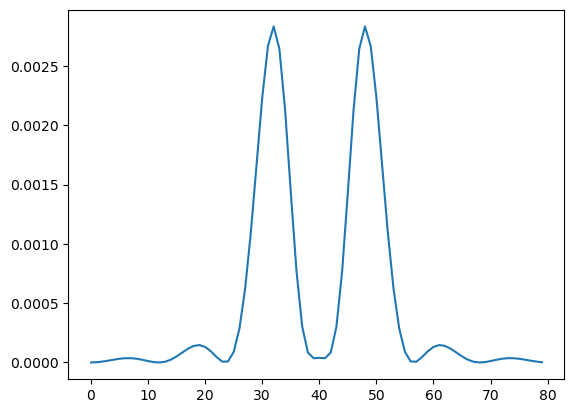

In [19]:
plt.plot(tensor[15,40,:])

# Quartic radial profile in Bottle Beam

The radial profile $A_{\mathrm{bb}}(r)$ $\approx$ $r^2 e^{-r^2/w^2}$.

The radial Intesity is $
I_{bb}(r) \approx \bigl(r^2 e^{-r^2/w^2}\bigr)^2 \;\approx\; r^4 - \frac{2r^6}{w^2} + \frac{2r^8}{w^4} - \cdots$

The axial Intensity is 
$$
I_{bb}(0,z)
\approx \ \frac{16\,(\ln 2)^2}{w^8\,f^2}\,z^2
\;-\;
\frac{16\,(\ln 2)^2\bigl((\ln 2)^2+12\bigr)}{3\,w^{12}\,f^4}\,z^4
\;+\;O(z^6).
$$



# Superposing a tweezer to make it quadratic
$$
A_{\rm tot}(r)
\;=\;
A_{bb}(r) \;+\; a\,e^{-r^2/w^2}
\;=\;
\bigl(r^2 + a\bigr)\,e^{-r^2/w^2}\,.
$$

Accordingly, the total intensity is

$$
I_{\rm tot}(r)
= \bigl(r^2 + a\bigr)^2\,e^{-2r^2/w^2}
\;\approx\;
a^2
\;+\;
\Bigl(2a - \tfrac{2a^2}{w^2}\Bigr)\,r^2
\;+\;
\Bigl(1 - \tfrac{4a}{w^2} + \tfrac{2a^2}{w^4}\Bigr)\,r^4
\;+\;O(r^6).
$$

$$
I_{\rm tot,\,norm}(r)
=\frac{I_{\rm tot}(r)}{\frac{w^2}{8}\Bigl[(w^2+a)^2 + a^2\Bigr]}
\;\approx\;
\underbrace{\frac{8\,a^2}{w^2\bigl[(w^2+a)^2 + a^2\bigr]}}_{r^0}
\;+\;
\underbrace{\frac{8\,(2a w^2 - 2a^2)}{w^4\bigl[(w^2+a)^2 + a^2\bigr]}}_{r^2}\,r^2
\;+\;
\underbrace{\frac{8\,(w^4 -4a w^2 + 2a^2)}{w^6\bigl[(w^2+a)^2 + a^2\bigr]}}_{r^4}\,r^4
\;+\;O(r^6).
$$



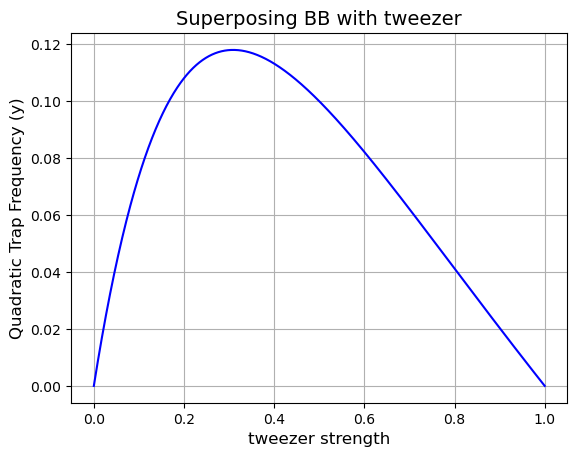

In [81]:
import numpy as np
import matplotlib.pyplot as plt

# Generate data
x = np.linspace(0, 1, 1000)
y = (x - x**2) / ((1 + x)**2 + x**2)

# Plot with labels and title
plt.figure()
plt.plot(x, y, color='blue')
plt.xlabel('tweezer strength', fontsize=12)
plt.ylabel('Quadratic Trap Frequency (y)', fontsize=12)
plt.title('Superposing BB with tweezer', fontsize=14)
plt.grid(True)
plt.show()


# Quadratic term in bottle beam by adjusting cutoff radius

The radial phase profile for a binary bottle-beam mask is given by

$$
\Phi(r) =
\begin{cases}
\pi, & r < R_0,\\
0,   & r \ge R_0,
\end{cases}
$$

where $R_0$ is the phase-step (cutoff) radius.  
For null intensity at center

$$
R_0 \;=\; w_{\mathrm{in}}\;\sqrt{\ln\!\Bigl(\tfrac{2}{1+e^{-H^2/w_{\mathrm{in}}^2}}\Bigr)}.
$$
Adjusting $R_0$  is close to superposing an additional “tweezer” potential, allowing a quadratic term  


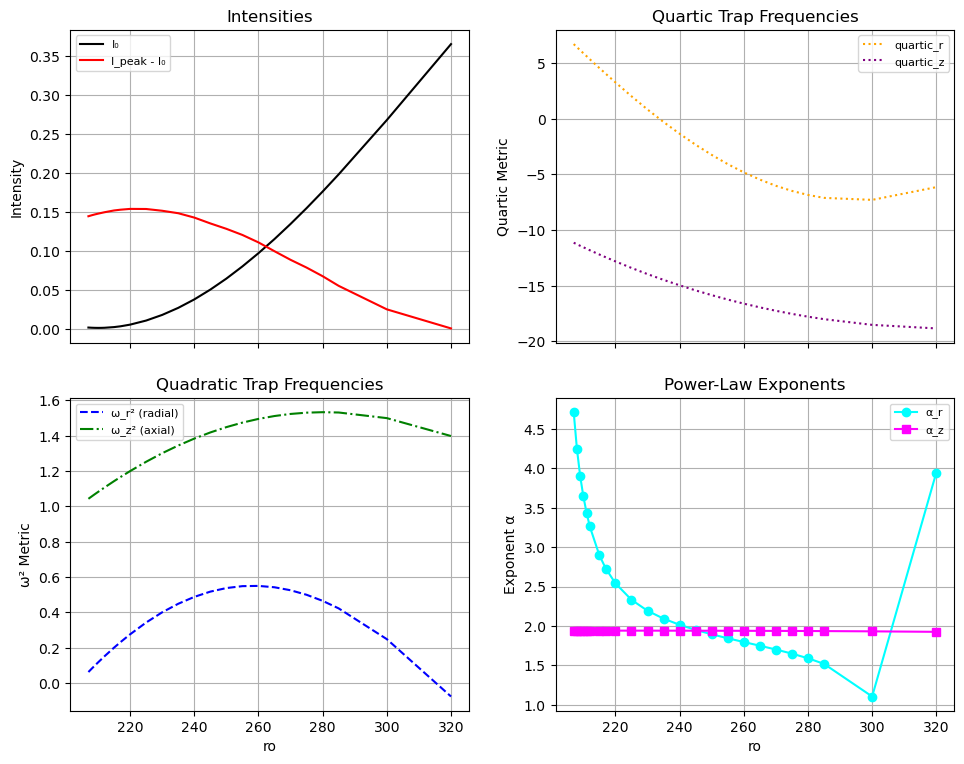

In [78]:
import matplotlib.pyplot as plt

# Ensure 'pdf' DataFrame is defined
try:
    pdf
except NameError:
    raise NameError("DataFrame 'pdf' is not defined. Please run: pdf = pd.DataFrame(results)")

# Create 2x2 grid of subplots
fig, axs = plt.subplots(2, 2, figsize=(10, 8), sharex=True)

# Top-left: Intensities
ax = axs[0, 0]
ax.plot(pdf['ro'], pdf['I_0'], color='black', label='I₀')
ax.plot(pdf['ro'], pdf['I_peak - I_0'], color='red', label='I_peak - I₀')
ax.set_ylabel('Intensity', fontsize=10)
ax.set_title('Intensities')
ax.legend(fontsize=8)
ax.grid(True)

# Bottom-left: Quadratic trap frequencies
ax = axs[1, 0]
ax.plot(pdf['ro'], pdf['second_radial_gradient'], color='blue', linestyle='--', label='ω_r² (radial)')
ax.plot(pdf['ro'], pdf['second_gradient_z'], color='green', linestyle='-.', label='ω_z² (axial)')
ax.set_xlabel('ro', fontsize=10)
ax.set_ylabel('ω² Metric', fontsize=10)
ax.set_title('Quadratic Trap Frequencies')
ax.legend(fontsize=8)
ax.grid(True)

# Top-right: Quartic trap frequencies
ax = axs[0, 1]
ax.plot(pdf['ro'], pdf['fourth_radial_gradient'], color='orange', linestyle=':', label='quartic_r')
ax.plot(pdf['ro'], pdf['fourth_gradient_z'], color='purple', linestyle=':', label='quartic_z')
ax.set_ylabel('Quartic Metric', fontsize=10)
ax.set_title('Quartic Trap Frequencies')
ax.legend(fontsize=8)
ax.grid(True)

# Bottom-right: Fit exponents
ax = axs[1, 1]
ax.plot(pdf['ro'], pdf['radial_fit_alpha'], color='cyan', marker='o', label='α_r')
ax.plot(pdf['ro'], pdf['z_fit_alpha'], color='magenta', marker='s', label='α_z')
ax.set_xlabel('ro', fontsize=10)
ax.set_ylabel('Exponent α', fontsize=10)
ax.set_title('Power-Law Exponents')
ax.legend(fontsize=8)
ax.grid(True)

plt.tight_layout(pad=2.0)
plt.show()


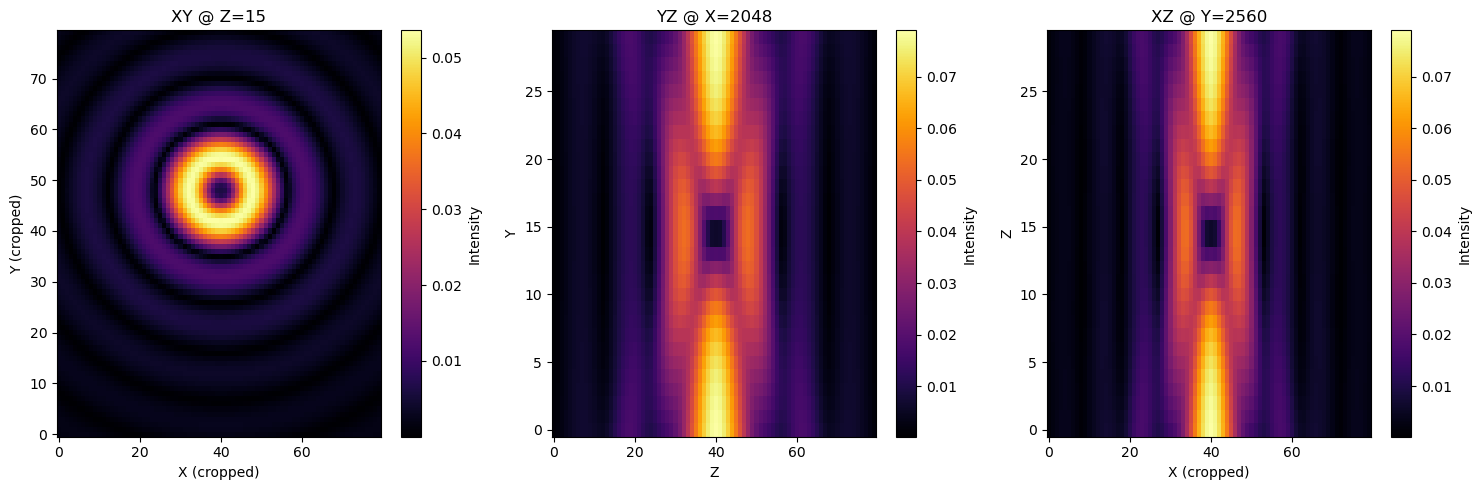

In [ ]:
plot_cropped_sections(tensors[260], m3d.pad_factor)

In [306]:
tensor = m3d.A_t[:,(512 - 10 )*m3d.pad_factor:(512 + 10 )*m3d.pad_factor,(640 - 10 )*m3d.pad_factor:(640 + 10 )*m3d.pad_factor]**2

In [307]:
1024

1024

In [45]:
import torch
import numpy as np
from scipy.optimize import curve_fit

def analyze_tensor(tensor: torch.Tensor,
                   pad_factor: float,
                   I_scale: float) -> dict:
    """
    Analyze a 3D intensity tensor and compute central intensities,
    radial and axial gradients, and power‐law fits.
    
    Parameters:
      tensor     -- torch.Tensor of shape (Z, X, Y)
      pad_factor -- float, padding factor used in pitch calculations
      I_scale    -- float, factor to normalize intensities
    
    Returns:
      dict with keys:
        I_0                      Center intensity in XY plane
        I_peak                   Peak intensity in XY plane
        I_peak - I_0             Difference between peak and center
        second_radial_gradient   2nd radial derivative at r=0
        fourth_radial_gradient   4th radial derivative at r=0
        radial_fit_a             a from fit I(r)-I0 = a r^α
        radial_fit_alpha         α from fit I(r)-I0 = a r^α
        second_gradient_z        2nd axial derivative at z=0
        fourth_gradient_z        4th axial derivative at z=0
        z_fit_a                  a from axial power-law fit
        z_fit_alpha              α from axial power-law fit
    """
    # constants
    lamda = 1.064
    w_in  = 2.53538014e+02

    # compute pitches
    w_t     = 1280 * pad_factor / (np.pi * w_in)
    pitch   = 1.125 / w_t
    pitch_z = 1.0 / (2.2e-1 * w_t**2 / lamda)

    # center indices
    Z, X, Y = tensor.shape
    z_idx    = Z // 2
    cx, cy   = X // 2, Y // 2

    # get central XY slice
    xy_plane = tensor[z_idx].cpu().numpy()

    # intensities
    I_0      = float(xy_plane[cx, cy])
    I_peak   = float(xy_plane.max())
    delta_I  = I_peak - I_0

    # radial profile along x-axis at y = center
    I_x      = xy_plane[:, cy]
    r_x      = (np.arange(X) - cx) * pitch
    r_xabs      = np.abs(r_x)  # use absolute distance from center

    # compute 1st–4th radial derivatives wrt r
    dI_dr    = np.gradient(I_x, r_x)
    d2I_dr2  = np.gradient(dI_dr, r_x)
    d3I_dr3  = np.gradient(d2I_dr2, r_x)
    d4I_dr4  = np.gradient(d3I_dr3, r_x)

    grad2_center = d2I_dr2[cx]
    grad4_center = d4I_dr4[cx]

    # fit radial power law near r = 0: I(r)-I0 = a * r^alpha
    def power_law(r, a, alpha):
        return a * r**alpha

    mask_r = r_xabs < 4 * pitch
    try:
        popt_radial, _ = curve_fit(power_law,
                                   r_xabs[mask_r],
                                   I_x[mask_r] - I_0,)
    except RuntimeError:
        popt_radial = [np.nan, np.nan]

    # axial (z) profile through center of XY
    z_profile = tensor[:, cx, cy].cpu().numpy()
    d2z       = np.gradient(np.gradient(z_profile, pitch_z), pitch_z)
    d4z       = np.gradient(np.gradient(d2z, pitch_z), pitch_z)

    # fit axial power law near z = 0: I(z)-I0 = a * z^alpha
    z_vals = np.abs(np.arange(Z) - z_idx) * pitch_z
    mask_z  = z_vals <= 2 * pitch_z
    try:
        popt_z, _ = curve_fit(power_law,
                              z_vals[mask_z],
                              z_profile[mask_z] - I_0)
    except RuntimeError:
        popt_z = [np.nan, np.nan]

    # compile results (all normalized by I_scale)
    results = {
        "I_0": I_0 / I_scale,
        "I_peak": I_peak / I_scale,
        "I_peak - I_0": delta_I / I_scale,
        "second_radial_gradient": grad2_center / I_scale,
        "fourth_radial_gradient": grad4_center / I_scale,
        "radial_fit_a": popt_radial[0] / I_scale,
        "radial_fit_alpha": popt_radial[1],
        "second_gradient_z": d2z[z_idx] / I_scale,
        "fourth_gradient_z": d4z[z_idx] / I_scale,
        "z_fit_a": popt_z[0] / I_scale,
        "z_fit_alpha": popt_z[1]
    }
    return results


In [55]:
tensors = []
ros = [207,208,217,225,235,245,255,265,270,275,280,285]
for ro in ros:
    targ2 = m3d.build_target_from_phase(torch.tensor(bottle_beam_phase(w_cutoff = ro)))
    tensor = m3d.A_t[:,(512 - 10 )*m3d.pad_factor:(512 + 10 )*m3d.pad_factor,(640 - 10 )*m3d.pad_factor:(640 + 10 )*m3d.pad_factor]**2
    tensors.append(tensor)


In [56]:
import os
import torch

# your lists


# make sure the folder exists
out_dir = "saved_tensors"
os.makedirs(out_dir, exist_ok=True)

# save each tensor
for ro, tensor in zip(ros, tensors):
    fn = os.path.join(out_dir, f"tensor_ro{ro}.pt")
    torch.save(tensor, fn)
    print(f"Saved ro={ro} → {fn}")


Saved ro=207 → saved_tensors/tensor_ro207.pt
Saved ro=208 → saved_tensors/tensor_ro208.pt
Saved ro=217 → saved_tensors/tensor_ro217.pt
Saved ro=225 → saved_tensors/tensor_ro225.pt
Saved ro=235 → saved_tensors/tensor_ro235.pt
Saved ro=245 → saved_tensors/tensor_ro245.pt
Saved ro=255 → saved_tensors/tensor_ro255.pt
Saved ro=265 → saved_tensors/tensor_ro265.pt
Saved ro=270 → saved_tensors/tensor_ro270.pt
Saved ro=275 → saved_tensors/tensor_ro275.pt
Saved ro=280 → saved_tensors/tensor_ro280.pt
Saved ro=285 → saved_tensors/tensor_ro285.pt


In [ ]:
tensor = targ2[:,(512 - 10 )*m3d.pad_factor:(512 + 10 )*m3d.pad_factor,(640 - 10 )*m3d.pad_factor:(640 + 10 )*m3d.pad_factor]**2

In [57]:
import os
import re
import torch

def load_tensors_by_ro(folder="saved_tensors"):
    """
    Load all .pt files in `folder`, extract the 'ro' value from filenames like
    'tensor_ro209.pt', and return a dict mapping ro → tensor.
    """
    ro_pattern = re.compile(r"tensor_ro(\d+)\.pt$")
    tensors_by_ro = {}

    for fn in os.listdir(folder):
        match = ro_pattern.match(fn)
        if not match:
            continue
        ro = int(match.group(1))
        path = os.path.join(folder, fn)
        tensors_by_ro[ro] = torch.load(path)

    return tensors_by_ro

# Usage
tensors_by_ro = load_tensors_by_ro("saved_tensors")
print("Loaded ros:", sorted(tensors_by_ro.keys()))
# e.g.
# tensor_for_215 = tensors_by_ro[215]


Loaded ros: [207, 208, 209, 210, 211, 212, 215, 217, 220, 225, 230, 235, 240, 245, 250, 255, 260, 265, 270, 275, 280, 285, 300, 320]


/var/folders/py/_lrzt4sd23jgrnhmp_01ng8h0000gn/T/ipykernel_68277/64849854.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  tensors_by_ro[ro] = torch.load(path)


In [59]:
from numpy import pad
results = []
for ro in tensors_by_ro.keys():
    result = analyze_tensor(tensors_by_ro[ro],pad_factor=4,I_scale=0.019006347568936686)
    result['ro'] = ro
    results.append(result)

In [64]:
import pandas as pd 
pdf = pd.DataFrame(results)
cols = pdf.columns.tolist()
cols.remove('ro')
pdf = pdf[['ro'] + cols]
pdf = pdf.sort_values('ro')

In [65]:
pdf

,ro,I_0,I_peak,I_peak - I_0,second_radial_gradient,fourth_radial_gradient,radial_fit_a,radial_fit_alpha,second_gradient_z,fourth_gradient_z,z_fit_a,z_fit_alpha
6,207,0.002437,0.147216,0.144778,0.062229,6.718272,0.526413,4.715646,1.042430,-11.143851,0.477314,1.939404
0,208,0.002203,0.148200,0.145998,0.080720,6.443136,0.420752,4.249791,1.055568,-11.281527,0.483347,1.939428
1,209,0.002058,0.149156,0.147098,0.098859,6.169718,0.361844,3.908441,1.068518,-11.417656,0.489292,1.939449
7,210,0.002002,0.150076,0.148074,0.116537,5.899861,0.325529,3.646893,1.081203,-11.551418,0.495113,1.939467
20,211,0.002032,0.151006,0.148974,0.133709,5.634222,0.301630,3.439870,1.093591,-11.682472,0.500797,1.939482
3,212,0.002153,0.152043,0.149890,0.151147,5.360879,0.284547,3.264624,1.106241,-11.816766,0.506599,1.939494
15,215,0.003027,0.155208,0.152181,0.200414,4.566273,0.257866,2.896692,1.142419,-12.203675,0.523183,1.939516
5,217,0.004029,0.157176,0.153147,0.231420,4.047497,0.249995,2.728511,1.165575,-12.453801,0.533789,1.939518
10,220,0.006171,0.160342,0.154172,0.275662,3.277348,0.244766,2.541065,1.199258,-12.821672,0.549202,1.939502
21,225,0.011395,0.165448,0.154053,0.342543,2.029484,0.243717,2.331429,1.252074,-13.410278,0.573327,1.939428


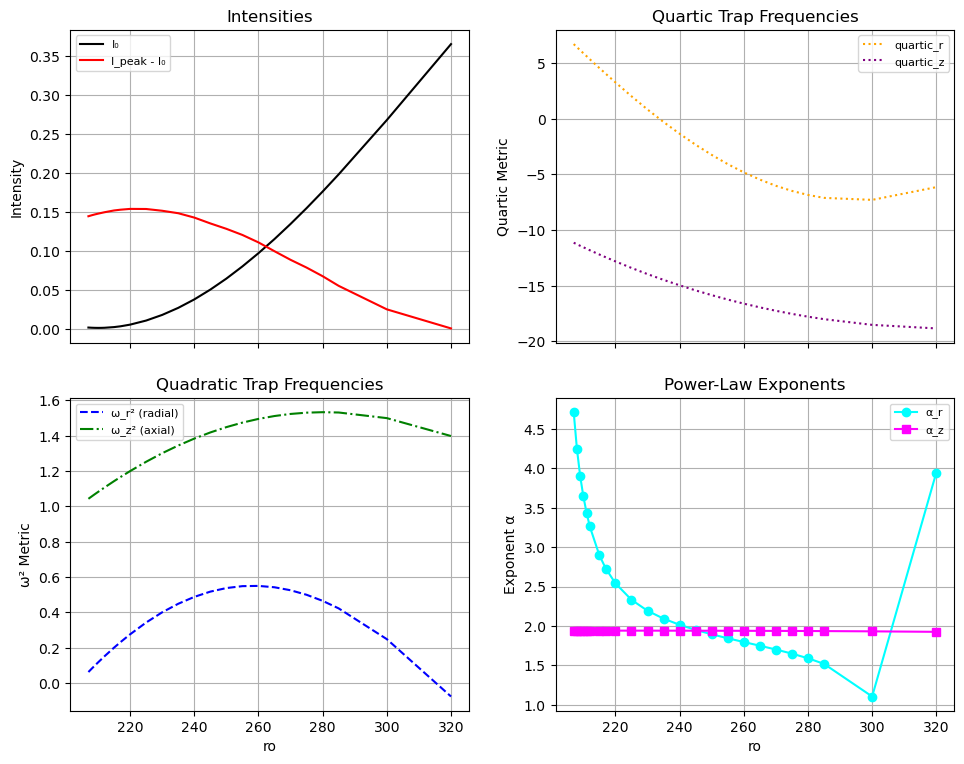

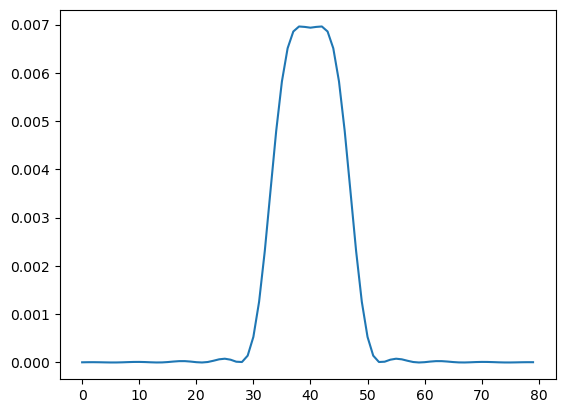

In [40]:
plt.plot(tensors[11][15,40,:])

In [21]:
from sympy import var
import torch
import numpy as np
from scipy.optimize import curve_fit
lamda = 1.064
# f = 600*1e3*1e-6
# delta_x = 6
# pitch_x = lamda*f/(1024*pad_factor*delta_x)
# pitch_y = lamda*f/(1280*pad_factor*delta_x)
# pitch = (pitch_x**2 + pitch_y**2)**0.5
w_in = 2.53538014e+02
w_t = 1280*pad_factor/(np.pi * w_in)
pitch = 1.125/w_t
pitch_x = pitch
pitch_y = pitch
zr = 2.2e-1*w_t**2/lamda
pitch_z = 1/zr
I_scale = 0.019006347568936686
# tensor: expected shape (30, 60, 60)
# tensor = your_tensor_here

z_idx = tensor.shape[0] // 2  # Middle slice in z-dimension
xy_plane = tensor[z_idx]
x_size, y_size = xy_plane.shape
cx, cy = x_size // 2, y_size // 2

# Intensity at center
I_0 = xy_plane[cx, cy].item()
I_peak = torch.max(xy_plane).item()
delta_I = I_peak - I_0

# Radial grid for fitting
yy, xx = np.meshgrid(np.arange(y_size), np.arange(x_size))
rr = np.sqrt(((xx - cx)**2) + (yy - cy)**2).flatten()*pitch
I_vals = xy_plane.numpy().flatten()

# Fit I(r) = a * r^alpha
def power_law(r, a, alpha):
    return a * r**alpha

mask =  (rr < 3*pitch)
try:
    popt_radial, _ = curve_fit(power_law, rr[mask], I_vals[mask]-I_0)
except RuntimeError:
    popt_radial = [np.nan, np.nan]

# # First derivatives
# grad_y, grad_x = np.gradient(xy_plane.numpy(),pitch_y, pitch_x)

# # Second derivatives
# grad2_xx = np.gradient(grad_x,pitch_x, axis=1)
# grad2_yy = np.gradient(grad_y,pitch_y, axis=0)
# grad2_center = 0.5 * (grad2_xx[cx, cy] + grad2_yy[cx, cy])

# # Fourth derivatives
# grad4_xxxx = np.gradient(np.gradient(grad2_xx,pitch_x, axis=1), axis=1)
# grad4_yyyy = np.gradient(np.gradient(grad2_yy,pitch_y, axis=0), axis=0)
# grad4_center = 0.5 * (grad4_xxxx[cx, cy] + grad4_yyyy[cx, cy])

# Radial derivatives of I(r)
# (rr and I_vals already defined)
I_x = xy_plane[:, cy]               # intensity along x-axis
r_x = (np.arange(x_size) - cx) * pitch  # radial coordinate along x

# Compute derivatives w.r.t. r
dI_dr   = np.gradient(I_x, r_x)
d2I_dr2 = np.gradient(dI_dr, r_x)
d3I_dr3 = np.gradient(d2I_dr2, r_x)
d4I_dr4 = np.gradient(d3I_dr3, r_x)

# Evaluate at the center (r = 0)
grad2_center = d2I_dr2[cx]
grad4_center = d4I_dr4[cx]






# z-profile at center
z_profile = tensor[:, cx, cy].numpy()
dz = np.gradient(z_profile,pitch_z)
d2z = np.gradient(dz,pitch_z)
d4z = np.gradient(np.gradient(d2z,pitch_z),pitch_z)

# Fit z-profile to power law
z_len = len(z_profile)
z_vals = np.abs(np.arange(z_len) - z_len // 2 )*pitch_z
mask_z = (z_vals <= 2*pitch_z)
try:
    popt_z, _ = curve_fit(power_law, z_vals[mask_z], z_profile[mask_z]-I_0)
except RuntimeError:
    popt_z = [np.nan, np.nan]

# Store results
results = {
    "I_0": I_0/I_scale,
    "I_peak": I_peak/I_scale,
    "I_peak - I_0": delta_I/I_scale,
    "second_gradient_xy_center": grad2_center/I_scale,
    "fourth_gradient_xy_center": grad4_center/I_scale,
    "radial_fit_a": popt_radial[0]/I_scale,
    "radial_fit_alpha": popt_radial[1],
    "second_gradient_z": d2z[z_idx]/I_scale,
    "fourth_gradient_z": d4z[z_idx]/I_scale,
    "z_fit_a": popt_z[0]/I_scale,
    "z_fit_alpha": popt_z[1]
}

print(results)


{'I_0': 0.0020579490100550335, 'I_peak': 0.14915574766263556, 'I_peak - I_0': 0.14709779865258055, 'second_gradient_xy_center': np.float64(0.09885888351335921), 'fourth_gradient_xy_center': np.float64(6.169717967337691), 'radial_fit_a': np.float64(0.28978260920752735), 'radial_fit_alpha': np.float64(4.038197782217782), 'second_gradient_z': np.float64(1.0685183044467175), 'fourth_gradient_z': np.float64(-11.41765602738569), 'z_fit_a': np.float64(0.48929185745275766), 'z_fit_alpha': np.float64(1.9394486593338738)}


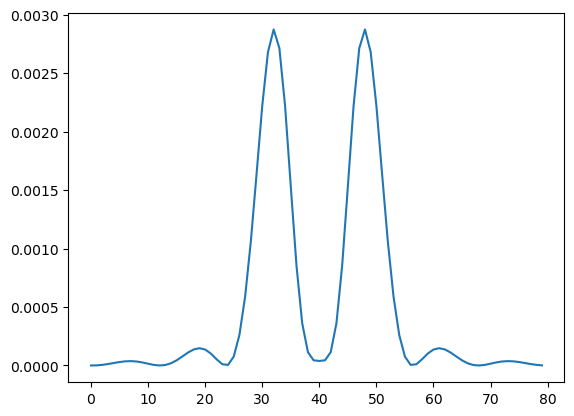

In [310]:
plt.plot(xy_plane.numpy()[cx, :], label='XY at center')

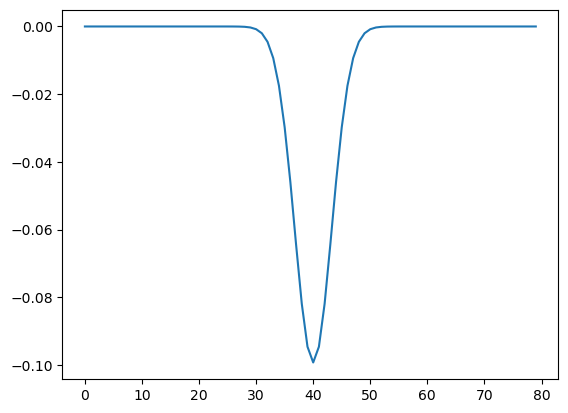

In [311]:
plt.plot(grad2_yy[cx,:]) 

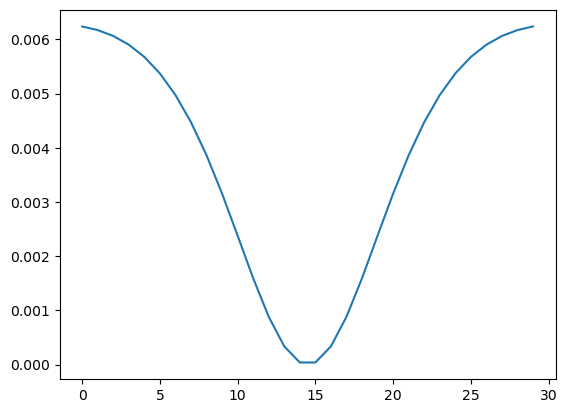

In [312]:
plt.plot(z_profile) 

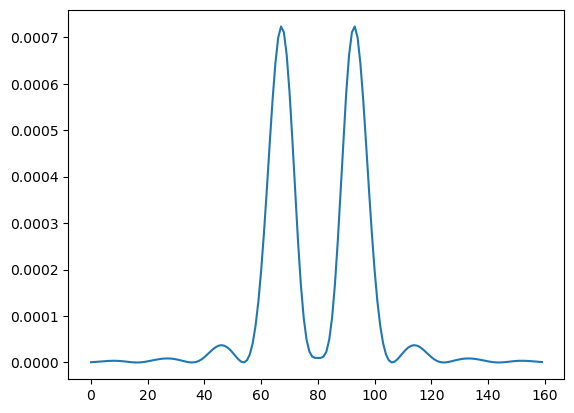

In [107]:
plt.plot(xy_plane.numpy()[:,cy]) 

In [49]:
grad2_xx[cx+4, cy+4] , grad2_yy[cx+4, cy+4]

(np.float64(-0.0007138225299374648), np.float64(-0.0021673068416271524))

$$
A_{bb}(k,z) = \int_{0}^{a} r\,e^{-r^2\left(\frac{1}{w_{\mathrm{in}}^2} + \frac{z}{2f}\right)}J_0(kr)\,dr
\;-\;
\int_{a}^{H} r\,e^{-r^2\left(\frac{1}{w_{\mathrm{in}}^2} + \frac{z}{2f}\right)}J_0(kr)\,dr
$$

$$
A_{bb}(0,z) = \int_{0}^{a} r\,e^{-r^2\left(\frac{1}{w_{\mathrm{in}}^2} + \frac{z}{2f}\right)}\,dr
\;-\;
\int_{a}^{H} r\,e^{-r^2\left(\frac{1}{w_{\mathrm{in}}^2} + \frac{z}{2f}\right)}\,dr
$$


$$
\text{Let }\alpha = \frac{1}{w_{\mathrm{in}}^2} + \frac{z}{2f}.
\quad\text{Then}
\quad
A_{bb}(0,z)
= \int_{0}^{a} r e^{-\alpha r^2}\,dr
  - \int_{a}^{H} r e^{-\alpha r^2}\,dr
= \frac{1 - 2e^{-\alpha a^2} + e^{-\alpha H^2}}{2\alpha}.
$$


$$
A_{bb}(0,z) \;=\;
\frac{w_{\mathrm{in}}^2}{2}\Bigl(1 - 2e^{-a^2/w_{\mathrm{in}}^2} + e^{-H^2/w_{\mathrm{in}}^2}\Bigr)
\;+\;
$$
$$
\frac{z}{4f}\Bigl[
w_{\mathrm{in}}^2\bigl(2a^2e^{-a^2/w_{\mathrm{in}}^2}-H^2e^{-H^2/w_{\mathrm{in}}^2}\bigr)
- w_{\mathrm{in}}^4\bigl(1 - 2e^{-a^2/w_{\mathrm{in}}^2} + e^{-H^2/w_{\mathrm{in}}^2}\bigr)
\Bigr]
+ O(z^2)\,.
$$




$$
A_{bb}(0,z)
\;=\;
\frac{1 - 2\,e^{-\alpha a^2}}{2\alpha}
\quad\text{with}\quad
\alpha = \frac{1}{w_{\mathrm{in}}^2} + \frac{z}{2f}.
$$


$$
A_{bb}(0,z)
\;=\;
\frac{1 - 2\exp\!\Bigl(-\bigl(\tfrac{1}{w_{\mathrm{in}}^2} + \tfrac{z}{2f}\bigr)\,w_{\mathrm{in}}^2\ln2\Bigr)}
{2\Bigl(\tfrac{1}{w_{\mathrm{in}}^2} + \tfrac{z}{2f}\Bigr)}.
$$



$$
A_{bb}(0,z)
= \frac{1 - \exp\!\Bigl(-\frac{w_{\mathrm{in}}^2\,\ln2}{2f}\,z\Bigr)}
{\displaystyle \frac{2}{w_{\mathrm{in}}^2} + \frac{z}{f}}.
$$


$$
I_{bb}(0,z)
= \bigl|A_{bb}(0,z)\bigr|^2
= \left(
  \frac{1 - \exp\!\bigl(-\tfrac{w_{\mathrm{in}}^2 \ln2}{2f}\,z\bigr)}
       {\displaystyle \frac{2}{w_{\mathrm{in}}^2} + \frac{z}{f}}
\right)^{2}
= \frac{\Bigl(1 - \exp\!\bigl(-\tfrac{w_{\mathrm{in}}^2 \ln2}{2f}\,z\bigr)\Bigr)^{2}}
       {\Bigl(\tfrac{2}{w_{\mathrm{in}}^2} + \tfrac{z}{f}\Bigr)^{2}}.
$$




In [ ]:
# write gr

NameError: name 'tensor' is not defined